In [1]:
import numpy as np

from exoplanet_finder.data_preparation.detrend import flatten_lightcurve
from exoplanet_finder.data_preparation.folding import bin_curve, fold
from exoplanet_finder.data_preparation.transform_units import hours_to_days
from exoplanet_finder.data_preparation.transit_math import transit_window_bounds
from exoplanet_finder.download_data.download import get_lightcurve, load_from_api
from exoplanet_finder.paths import KOI_TABLE_PATH, LIGHT_CURVES_DIR
from exoplanet_finder.visualizations.graphs import plot_binned_curve

#Get data
query = (
    "select kepid, kepoi_name, kepler_name, koi_disposition, koi_fpflag_ss, "
    "koi_period, koi_time0bk, koi_duration, koi_depth from cumulative"
)
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?"

table = load_from_api(url, query, KOI_TABLE_PATH)
table.head()

/home/viktor/Exoplanet_Finder/.venv/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


,kepid,kepoi_name,kepler_name,koi_disposition,koi_fpflag_ss,koi_period,koi_time0bk,koi_duration,koi_depth
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,0,9.488036,170.538750,2.95750,615.8
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,0,54.418383,162.513840,4.50700,874.8
2,10811496,K00753.01,NaN,CANDIDATE,0,19.899140,175.850252,1.78220,10829.0
3,10848459,K00754.01,NaN,FALSE POSITIVE,1,1.736952,170.307565,2.40641,8079.2
4,10854555,K00755.01,Kepler-664 b,CONFIRMED,0,2.525592,171.595550,1.65450,603.3


In [2]:
#Get data about light curves
kepid = table["kepid"][0]
light_curve = get_lightcurve(kepid, LIGHT_CURVES_DIR)

In [3]:
#get usefull units
table["koi_duration_days"] = hours_to_days(table["koi_duration"])

In [4]:
#flatten
star_kois = table[table["kepid"] == kepid]

flat = flatten_lightcurve(
    light_curve,
    star_kois["koi_period"],
    star_kois["koi_time0bk"],
    star_kois["koi_duration_days"],
)

In [5]:
#Get numpy pole
np_light_curve = np.column_stack([flat.time.value, flat.flux.value])

In [6]:
#fold and bin function
fold_light_curve = fold(np_light_curve, table["koi_period"][0], table["koi_time0bk"][0])
low, high = transit_window_bounds(table["koi_duration_days"][0], 1.5)
bin_light_curve = bin_curve(fold_light_curve, 50, low, high)

<Axes: title={'center': 'K00752.01 (CONFIRMED)'}, xlabel='Time from transit center [hours]', ylabel='Flux change [ppm]'>

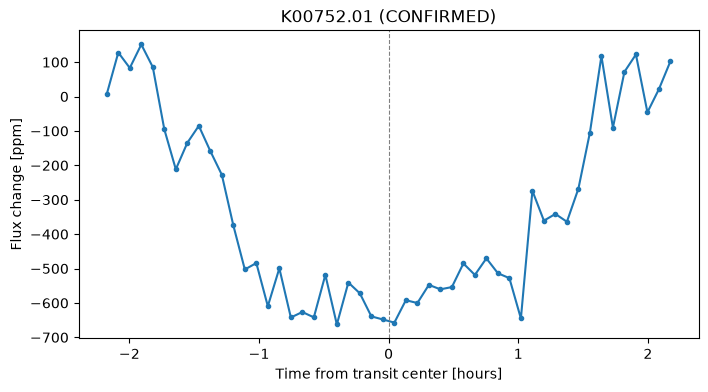

In [7]:
#Blit graph
plot_binned_curve(bin_light_curve, low, high, f"{table['kepoi_name'][0]} ({table['koi_disposition'][0]})")
